# 08. レイアウト品質評価指標とマルチアルゴリズム比較ベンチマーク

このノートブックでは、`egraph` v6 が提供する **統合評価関数 `evaluate_metrics`（全 42 指標）** および **全 58 種の単体評価関数**（ストレス／BFS・交差／角度／幾何・近傍保持／近接グラフ／RTA・コミュニティ／クラスタ分離／重なり・NOR）を網羅的に学びます。

後半では、代表的な 7 種のレイアウトアルゴリズム（`SgdSolver.full`, `StressMajorizationSolver`, `TsNetSolver`, `IbUmapSolver`, `ForceAtlas2Solver`, `YifanHuSolver`, `SgdSolver.sparse_barrier_dog`）を `dwt_1005` および 4 クラスタ確率的ブロックモデル（SBM）上で定量比較し、`matplotlib` によるレイアウト一覧・棒グラフ・正規化レーダーチャート・トレードオフ散布図を描画します。

In [ ]:
!pip install -q --pre "egraph==6.0.0a8" matplotlib-fontja

## 1. 環境設定と可視化ヘルパー関数

プロットはすべて `matplotlib` の `LineCollection` と `ax.scatter` のみを用いて描画します。

In [ ]:
import time
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle

# Apply Japanese font on Colab when matplotlib-fontja is installed
try:
    import matplotlib_fontja  # noqa: F401
except ImportError:
    pass

import egraph as eg
from egraph.interop import from_networkx

plt.rcParams["figure.dpi"] = 120
print(f"egraph version: {eg.__version__}")


def plot_layout(
    graph: eg.CsrGraph,
    layout: eg.Layout2d,
    ax=None,
    *,
    labels=None,
    title: str = "",
    node_size: float = 14.0,
    edge_alpha: float = 0.18,
    edge_width: float = 0.45,
):
    '''Plot a CsrGraph and Layout2d strictly via matplotlib LineCollection + scatter.'''
    if ax is None:
        _, ax = plt.subplots(figsize=(5.0, 4.5))

    coords = layout.coords(copy=False)
    indptr = graph.indptr()
    indices = graph.indices()
    segs = []
    for u in range(graph.num_nodes):
        for v in indices[int(indptr[u]) : int(indptr[u + 1])]:
            v_int = int(v)
            if u < v_int:
                segs.append([coords[u], coords[v_int]])
    if segs:
        ax.add_collection(LineCollection(segs, colors="#777777", linewidths=edge_width, alpha=edge_alpha, zorder=1))

    if labels is not None:
        ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c=labels, cmap="tab10", edgecolors="white", linewidths=0.25, zorder=2)
    else:
        ax.scatter(coords[:, 0], coords[:, 1], s=node_size, c="#1f77b4", edgecolors="white", linewidths=0.25, zorder=2)

    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.set_xticks([])
    ax.set_yticks([])
    if title:
        ax.set_title(title, fontsize=9)
    return ax

egraph version: 6.0.0a8


## 2. `evaluate_metrics` 統合評価ディスパッチャ（全 42 指標・エイリアス・注意点）

`evaluate_metrics(graph, layout, targets, *, ...)` は、指定した複数指標を 1 回の呼び出しで計算し、アルファベット順の `dict[str, float]` を返します。

### 主な仕様と注意点
1. **全 42 ターゲット**: 幾何・ストレス・交差・近傍保持・RTA 系（22 指標 + `sprawlter_nn` の計 **23 指標**）と、コミュニティラベル必須のクラスタ／コミュニティ系（**19 指標**）の合計 **42 指標** をサポートします。
2. **ターゲット文字列の正規化**: 大文字・小文字を区別せず、`_` と `-` を除去して照合します（例: `"SNS"`, `"sweep-crossing-number"`, `"gcaf"`, `"rta"`）。※ 空白文字は除去されないためご注意ください。
3. **`community_labels` 必須チェック**: コミュニティ系 19 指標のいずれかを `community_labels=None` で呼び出すと `ValueError` が送出されます（`sprawlter_nn` はコミュニティ不要で計算可能）。
4. **重み付きグラフと `ideal_edge_length`**: `graph.is_weighted == True` のとき、`evaluate_metrics(..., ideal_edge_length=...)` は引数を無視してグラフ辺重みを理想辺長として使用します。
5. **小規模グラフにおける `adjusted_patch_nig`**: デフォルトの `canvas_size=2048, patch_radius=8` では頂点数が少ない疎な配置（`lesmis` や `SBM_160` 等）で 1 セルあたり 1 頂点以下となり `0.0` に潰れることがあります。小規模グラフでは `patch_radius=32, canvas_size=256` 等を調整するか、`dwt_1005` のような中〜大規模グラフでデフォルト値を用います。

In [ ]:
# Prepare 'dwt_1005' with Leiden communities so all 42 evaluate_metrics targets are valid at defaults
g_dwt = eg.load_dataset("dwt_1005")
leiden_dwt = eg.leiden_communities(g_dwt, seed=42)
labels_dwt = leiden_dwt["labels"]

l_dwt_sgd = eg.pivot_mds_init(g_dwt, num_pivots=50, seed=42)
eg.SgdSolver.full(g_dwt, t_max=60, seed=42).run(l_dwt_sgd)

ALL_42_TARGETS = [
    # 23 geometry / stress / crossing / neighborhood / RTA / sprawlter targets (no community_labels required)
    "scale_normalized_stress",
    "sampled_scale_normalized_stress",
    "crossing_number",
    "crossing_angle",
    "sampled_crossing_number",
    "crosslessness",
    "sampled_crosslessness",
    "neighborhood_preservation_1hop",
    "neighborhood_preservation_2hop",
    "sampled_np1",
    "sampled_np2",
    "gabriel_graph_property",
    "node_resolution",
    "relative_neighborhood_preservation",
    "gabriel_graph_preservation",
    "aspect_ratio",
    "angular_resolution",
    "minimum_angle",
    "minimum_angle_a1",
    "layout_degeneracy",
    "ideal_edge_lengths",
    "landmark_stratified_rta",
    "sprawlter_nn",
    # 19 community / cluster targets (require community_labels)
    "adjusted_patch_nig",
    "cluster_area_faithfulness",
    "dsc",
    "dc",
    "cdm",
    "hdm",
    "sepme_knng",
    "sepme_rng",
    "sepme_gab",
    "sepme_gong",
    "neighborhood_hit",
    "silhouette",
    "calinski_harabasz",
    "davies_bouldin",
    "cq_kmeans_ari",
    "cq_kmeans_ami",
    "cq_hac_hom",
    "cq_hac_ami",
    "pairwise_distance_overlap_error",
]

res_42 = eg.evaluate_metrics(
    g_dwt,
    l_dwt_sgd,
    ALL_42_TARGETS,
    community_labels=labels_dwt,
    num_pivots=64,
    num_samples=4096,
    num_landmarks=32,
    num_triplets=50000,
    patch_radius=8,
    canvas_size=2048,
    g_max=128,
    sprawlter_node_radius=0.5,
    ideal_edge_length=1.0,
    dc_grid_size=20,
    cdm_grid_size=64,
    sepme_knng_k=2,
    neighborhood_hit_k=7,
    gong_gamma=0.35,
    kmeans_n_init=5,
    kmeans_max_iters=100,
    num_bins=100,
    seed=42,
)
print(f"Returned {len(res_42)} / {len(ALL_42_TARGETS)} canonical targets:")
for idx, (k, v) in enumerate(res_42.items(), 1):
    print(f"  {idx:2d}. {k:<36s} = {v:.6f}")

# Alias normalization test (case / underscore / hyphen insensitive)
alias_res = eg.evaluate_metrics(
    g_dwt,
    l_dwt_sgd,
    ["SNS", "NP2", "sweep-crossing-number", "gcaf", "rta", "mnh", "ch", "db", "pdoe"],
    community_labels=labels_dwt,
    num_triplets=20000,
)
print("\nAlias resolution keys:", sorted(alias_res.keys()))

# Verify ValueError when a community target is invoked without community_labels
try:
    eg.evaluate_metrics(g_dwt, l_dwt_sgd, ["cluster_area_faithfulness"])
except ValueError as err:
    print("Expected ValueError without community_labels:", err)

Returned 42 / 42 canonical targets:
   1. adjusted_patch_nig                   = 0.903391
   2. angular_resolution                   = 8496.232521
   3. aspect_ratio                         = 0.996554
   4. calinski_harabasz                    = 870.367912
   5. cdm                                  = 0.978302
   6. cluster_area_faithfulness            = 0.803556
   7. cq_hac_ami                           = 0.701711
   8. cq_hac_hom                           = 0.695574
   9. cq_kmeans_ami                        = 0.731742
  10. cq_kmeans_ari                        = 0.543393
  11. crossing_angle                       = 2664.048945
  12. crossing_number                      = 8067.000000
  13. crosslessness                        = 0.966567
  14. davies_bouldin                       = 0.751386
  15. dc                                   = 0.936775
  16. dsc                                  = 0.865672
  17. gabriel_graph_preservation           = 0.309707
  18. gabriel_graph_property       

## 3. 単体指標グループ A: ストレス & BFS 最短経路距離（5 関数）

- `scale_normalized_stress(graph, layout)` / `sampled_scale_normalized_stress(graph, layout, *, num_pivots=64, seed=42)`
- `scale_normalized_stress_from_distances(layout, distances, weights=None)`: 任意の距離行列 $D \in \mathbb{R}^{N \times N}$ に対する SNS を計算します（※ 対称行列の上三角 $i < j$ のみを参照する仕様のため、対称行列を渡してください）。
- `all_pairs_bfs(graph, unit_edge_length=1.0)` / `bfs_single_source(graph, source, unit_edge_length=1.0)`: 非連結頂点ペアは `np.inf` になります。

In [ ]:
g_les = eg.load_dataset("lesmis")
l_les = eg.Layout2d.init(g_les.num_nodes, seed=42)
eg.SgdSolver.full(g_les, t_max=60, seed=42).run(l_les)

d_all = eg.all_pairs_bfs(g_les, unit_edge_length=1.0)
d_src0 = eg.bfs_single_source(g_les, 0, unit_edge_length=1.0)

sns_exact = eg.scale_normalized_stress(g_les, l_les)
sns_sampled = eg.sampled_scale_normalized_stress(g_les, l_les, num_pivots=32, seed=42)
sns_from_mat = eg.scale_normalized_stress_from_distances(l_les, d_all)
sns_custom_w = eg.scale_normalized_stress_from_distances(
    l_les, d_all, weights=np.where(d_all > 0, 1.0 / np.maximum(d_all, 1.0), 0.0)
)

print(f"lesmis all_pairs_bfs shape={d_all.shape}, bfs_single_source(0)[:8]={d_src0[:8]}")
print(f"scale_normalized_stress               = {sns_exact:.6f}")
print(f"scale_normalized_stress_from_distances = {sns_from_mat:.6f} (diff={abs(sns_exact - sns_from_mat):.2e})")
print(f"sampled_scale_normalized_stress(p=32)  = {sns_sampled:.6f}")
print(f"custom 1/d weighted SNS                = {sns_custom_w:.6f}")

# Check unreachable nodes on disconnected 'poli'
g_poli = eg.load_dataset("poli")
d_poli_0 = eg.bfs_single_source(g_poli, 0)
print(f"poli bfs_single_source(0): finite={np.isfinite(d_poli_0).sum()}, inf={np.isinf(d_poli_0).sum()}")

lesmis all_pairs_bfs shape=(77, 77), bfs_single_source(0)[:8]=[0. 1. 1. 1. 1. 1. 1. 1.]
scale_normalized_stress               = 0.082906
scale_normalized_stress_from_distances = 0.082906 (diff=6.22e-15)
sampled_scale_normalized_stress(p=32)  = 0.081801
custom 1/d weighted SNS                = 0.073269
poli bfs_single_source(0): finite=2343, inf=1572


## 4. 単体指標グループ B: 交差数・交差角・最小角・幾何指標・歪み（20 関数）

このグループでは平面・トーラス上の交差・角度・幾何的バランスおよび配置の縮退・オーバーラップ除去後の歪みを計測します。

- **交差系**: `sweep_crossing_number`, `sweep_crossing_angle`, `sampled_crossing_number`, `crosslessness`, `sampled_crosslessness`, `crossing_summary`, `crossing_edges`, `torus_crossing_number`, `crossing_edges_torus`
- **角度・幾何系**: `minimum_angle`, `minimum_angle_summary` (`a1` vs `a2`), `edge_angle`, `angular_resolution_v6`, `aspect_ratio_v6`, `node_resolution_v6`, `ideal_edge_lengths_v6`, `ideal_edge_lengths_with_unit`, `layout_degeneracy`（11 キーの診断辞書を返す。`evaluate_metrics` では最大ペナルティのスカラー値になる点に注意）
- **変形歪み系**: `prism_distortion(orig, adj)`, `prism_distortion_with_edges(orig, adj, edges)`

In [ ]:
# 1) Crossings & angles on lesmis
c_num = eg.sweep_crossing_number(g_les, l_les)
c_ang = eg.sweep_crossing_angle(g_les, l_les)
c_samp = eg.sampled_crossing_number(g_les, l_les, num_samples=4096, seed=42)
cless = eg.crosslessness(g_les, l_les)
cless_samp = eg.sampled_crosslessness(g_les, l_les, num_samples=4096, seed=42)
c_sum = eg.crossing_summary(g_les, l_les)
c_edges = eg.crossing_edges(g_les, l_les)

min_ang = eg.minimum_angle(g_les, l_les)
min_ang_sum = eg.minimum_angle_summary(g_les, l_les)
ang_uv = eg.edge_angle(1.0, 0.0, 0.0, 1.0)
ang_res = eg.angular_resolution_v6(g_les, l_les)
asp_ratio = eg.aspect_ratio_v6(l_les)
node_res = eg.node_resolution_v6(l_les)
iel_v6 = eg.ideal_edge_lengths_v6(g_les, l_les)
iel_u2 = eg.ideal_edge_lengths_with_unit(g_les, l_les, 2.0)
degen = eg.layout_degeneracy(g_les, l_les)

print(f"Crossings: sweep={c_num:.0f}, sampled={c_samp:.1f}, angle_cos2={c_ang:.3f}, crosslessness={cless:.4f}, sampled={cless_samp:.4f}")
print("crossing_summary:", c_sum)
print(f"crossing_edges count={len(c_edges)}, sample[0]={c_edges[0] if c_edges else None}")
print(f"minimum_angle={min_ang:.4f}, summary={min_ang_sum}, edge_angle((1,0),(0,1))={ang_uv:.4f} rad")
print(f"angular_res={ang_res:.3f}, aspect_ratio={asp_ratio:.4f}, node_res={node_res:.4f}, iel_v6={iel_v6:.4f}, iel_unit2={iel_u2:.4f}")
print("layout_degeneracy keys:", list(degen.keys()), "bbox:", round(degen["bbox_width"], 2), "x", round(degen["bbox_height"], 2))

# 2) Weighted graph quirk: evaluate_metrics ignores ideal_edge_length when graph.is_weighted == True
g_weighted = eg.CsrGraph.from_edges(4, np.array([[0, 1], [1, 2], [2, 3], [3, 0]], dtype=np.uint32), weights=np.array([1.0, 1.0, 1.0, 1.0]))
l_sq = eg.Layout2d.from_coords(np.array([[0.0, 0.0], [2.0, 0.0], [2.0, 2.0], [0.0, 2.0]]))
print(
    f"Weighted quirk: eval_metrics(ideal=2.0)={eg.evaluate_metrics(g_weighted, l_sq, ['ideal_edge_lengths'], ideal_edge_length=2.0)['ideal_edge_lengths']:.4f} "
    f"vs ideal_edge_lengths_with_unit(2.0)={eg.ideal_edge_lengths_with_unit(g_weighted, l_sq, 2.0):.4f}"
)

# 3) Torus crossings on unit [0, 1)^2 square (also covered in NB07)
g_tor_small, _ = from_networkx(nx.grid_2d_graph(4, 4, periodic=True))
m_tor_small = eg.ManifoldLayout2d.random_init("torus", g_tor_small.num_nodes, seed=42)
eg.SgdSolver.full(g_tor_small, t_max=50, seed=42).run_manifold(m_tor_small)
l_tor_euc = m_tor_small.to_layout()
print(
    f"4x4 torus: torus_crossing_number={eg.torus_crossing_number(g_tor_small, l_tor_euc):.1f}, "
    f"crossing_edges_torus len={len(eg.crossing_edges_torus(g_tor_small, l_tor_euc))}"
)

# 4) Prism distortion after overlap removal
hw_les = np.full(g_les.num_nodes, 0.25)
hh_les = np.full(g_les.num_nodes, 0.18)
l_les_adj = eg.Layout2d.from_coords(l_les.coords(copy=True))
eg.PrismOverlapRemoval(hw_les, hh_les).run(l_les_adj)
gg_edges = eg.gabriel_graph_edges(l_les)
pd_default = eg.prism_distortion(l_les, l_les_adj)
pd_explicit = eg.prism_distortion_with_edges(l_les, l_les_adj, gg_edges)
print(f"prism_distortion={pd_default}, prism_distortion_with_edges(gabriel)={pd_explicit}")

Crossings: sweep=974, sampled=941.3, angle_cos2=273.324, crosslessness=0.8177, sampled=0.8208
crossing_summary: {'count': 974, 'angle_cos_sq_sum': 273.3236768846288, 'min_angle_rad': 0.08790720689367246}
crossing_edges count=974, sample[0]={'edge_a': 9, 'edge_b': 10, 'u1': 0, 'v1': 11, 'u2': 2, 'v2': 3, 'angle_rad': 1.567847956040814, 'cos_sq': 8.69286491477962e-06}
minimum_angle=0.3622, summary={'a1': 0.36223420796454137, 'a2': 0.36223420796454137}, edge_angle((1,0),(0,1))=1.5708 rad
angular_res=924.886, aspect_ratio=0.9404, node_res=21.1149, iel_v6=31.5788, iel_unit2=81.4619
layout_degeneracy keys: ['num_nodes', 'num_edges', 'duplicate_nodes_f32', 'duplicate_ratio_f32', 'duplicate_nodes_f64', 'duplicate_ratio_f64', 'zero_length_edges', 'zero_length_edge_ratio', 'bbox_width', 'bbox_height', 'is_bbox_degenerate'] bbox: 5.29 x 6.07
Weighted quirk: eval_metrics(ideal=2.0)=4.0000 vs ideal_edge_lengths_with_unit(2.0)=0.0000
4x4 torus: torus_crossing_number=35.0, crossing_edges_torus len=35

## 5. 単体指標グループ C: 近傍保持・近接グラフ・ランドマーク層別 RTA（12 関数）

- **近傍保持**: `neighborhood_preservation_1hop`, `neighborhood_preservation_2hop_v6`, `sampled_np1`, `sampled_np2`
- **近接グラフ保持**: `drng_preservation` ($S_{\mathrm{RNG}}$), `dgg_preservation` ($S_{\mathrm{GG}}$), `gabriel_graph_property_v6`, `gabriel_graph_edges`, `relative_neighborhood_edges`
- **ランキング順位保存（RTA）**: `landmark_stratified_rta`, `landmark_stratified_rta_detail`, `landmark_stratified_rta_from_landmarks`

> **実装上の注意 (`landmark_stratified_rta_from_landmarks`)**: `all_pairs_bfs` や `bfs_single_source` は到達不能頂点を `float64` の `np.inf` で返しますが、そのまま `.astype(np.uint32)` しても `u32::MAX` (`2**32 - 1`) にはなりません。必ず `np.where(np.isfinite(d), d, 2**32 - 1).astype(np.uint32)` で変換してから渡してください。

NP1=0.4290 (sampled=0.4290), NP2=0.6924 (sampled=0.6924)
DRNG=0.1287, DGG=0.2023, gabriel_property=34.5517, len(GG)=154, len(RNG)=93
RTA=0.9112, detail={'rta': 0.9111555041530859, 'num_landmarks': 16, 'num_triplets': 28533, 'num_strata': 5, 'is_exact': True}
RTA from precomputed MaxMin landmarks={'rta': 0.9111555041530859, 'num_landmarks': 16, 'num_triplets': 28533, 'num_strata': 5, 'is_exact': True}


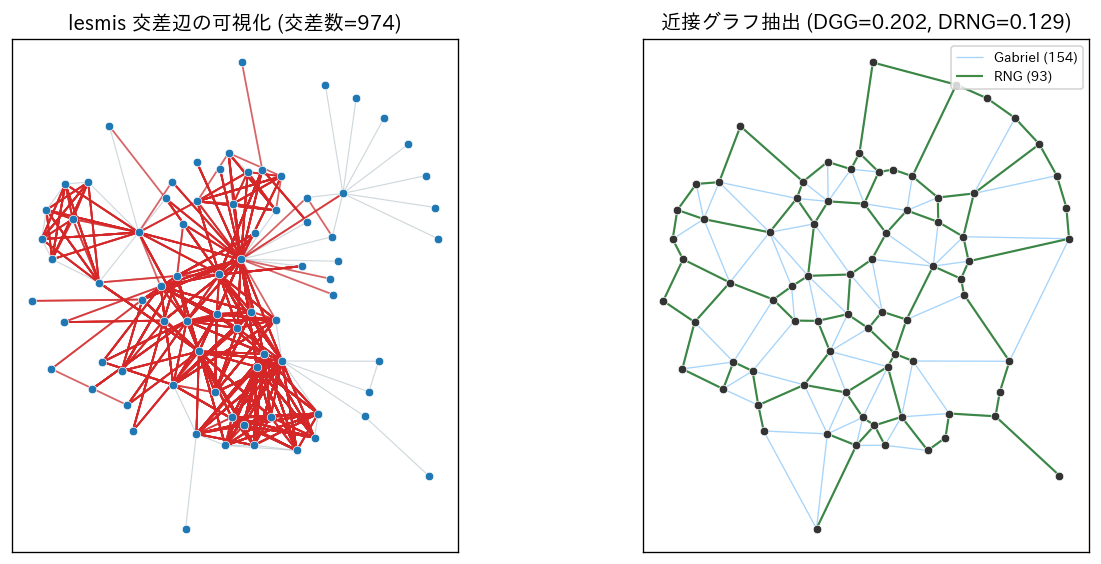

In [ ]:
np1 = eg.neighborhood_preservation_1hop(g_les, l_les)
np2 = eg.neighborhood_preservation_2hop_v6(g_les, l_les)
snp1 = eg.sampled_np1(g_les, l_les, num_samples=2048, seed=42)
snp2 = eg.sampled_np2(g_les, l_les, num_samples=2048, seed=42)
drng = eg.drng_preservation(g_les, l_les)
dgg = eg.dgg_preservation(g_les, l_les)
gg_prop = eg.gabriel_graph_property_v6(g_les, l_les)
rng_edges = eg.relative_neighborhood_edges(l_les)

rta_val = eg.landmark_stratified_rta(g_les, l_les, num_landmarks=16, num_triplets=50000, seed=42)
rta_det = eg.landmark_stratified_rta_detail(g_les, l_les, num_landmarks=16, num_triplets=50000, seed=42)

# Precomputed landmark BFS distance table with safe np.inf -> uint32::MAX conversion
lm_ids = eg.select_maxmin_sp_pivots(g_les, num_pivots=16, seed=42)
lm_dists_f64 = np.vstack([eg.bfs_single_source(g_les, int(u)) for u in lm_ids])
lm_dists_u32 = np.where(np.isfinite(lm_dists_f64), lm_dists_f64, 2**32 - 1).astype(np.uint32)
rta_from_lm = eg.landmark_stratified_rta_from_landmarks(l_les, lm_ids, lm_dists_u32, num_triplets=50000, seed=42)

print(f"NP1={np1:.4f} (sampled={snp1:.4f}), NP2={np2:.4f} (sampled={snp2:.4f})")
print(f"DRNG={drng:.4f}, DGG={dgg:.4f}, gabriel_property={gg_prop:.4f}, len(GG)={len(gg_edges)}, len(RNG)={len(rng_edges)}")
print(f"RTA={rta_val:.4f}, detail={rta_det}")
print(f"RTA from precomputed MaxMin landmarks={rta_from_lm}")

# Visualize crossing edges (red) vs Gabriel / RNG proximity graphs on lesmis
coords_les = l_les.coords(copy=False)
indptr_les, indices_les = g_les.indptr(), g_les.indices()
all_edge_segs = [
    [coords_les[u], coords_les[int(v)]]
    for u in range(g_les.num_nodes)
    for v in indices_les[int(indptr_les[u]) : int(indptr_les[u + 1])]
    if u < int(v)
]
cross_segs = []
for ce in c_edges:
    cross_segs.append([coords_les[ce["u1"]], coords_les[ce["v1"]]])
    cross_segs.append([coords_les[ce["u2"]], coords_les[ce["v2"]]])

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
axes[0].add_collection(LineCollection(all_edge_segs, colors="#b0bec5", linewidths=0.7, alpha=0.6))
if cross_segs:
    axes[0].add_collection(LineCollection(cross_segs, colors="#d62728", linewidths=1.1, alpha=0.65))
axes[0].scatter(coords_les[:, 0], coords_les[:, 1], s=26, c="#1f77b4", edgecolors="white", linewidths=0.4, zorder=3)
axes[0].set_aspect("equal")
axes[0].autoscale_view()
axes[0].set_xticks([])
axes[0].set_yticks([])
axes[0].set_title(f"lesmis 交差辺の可視化 (交差数={int(c_num)})")

gg_segs = [[coords_les[u], coords_les[v]] for u, v in gg_edges]
rng_segs = [[coords_les[u], coords_les[v]] for u, v in rng_edges]
axes[1].add_collection(LineCollection(gg_segs, colors="#90caf9", linewidths=0.8, alpha=0.8, label=f"Gabriel ({len(gg_edges)})"))
axes[1].add_collection(LineCollection(rng_segs, colors="#2e7d32", linewidths=1.3, alpha=0.9, label=f"RNG ({len(rng_edges)})"))
axes[1].scatter(coords_les[:, 0], coords_les[:, 1], s=26, c="#333333", edgecolors="white", linewidths=0.4, zorder=3)
axes[1].set_aspect("equal")
axes[1].autoscale_view()
axes[1].set_xticks([])
axes[1].set_yticks([])
axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_title(f"近接グラフ抽出 (DGG={dgg:.3f}, DRNG={drng:.3f})")
plt.tight_layout()
plt.show()

## 6. 単体指標グループ D: コミュニティ・クラスタ品質・重なり／NOR（21 関数）

グラウンドトゥルース（あるいは `leiden_communities` で抽出したラベル）に対する 2 次元配置の分離性・面積忠実性・クラスタリング整合性、および重なり除去の忠実度（`sprawlter_nn`, `nor_metrics`）を評価します。

- **G-CAF & Patch NIG**: `adjusted_patch_nig`, `adjusted_patch_nig_multiscale`, `cluster_area_faithfulness`, `cluster_area_faithfulness_detail(..., return_per_cluster=True)`
- **外部クラスタリング一致 & 教師なし整合性**: `partition_agreement`, `cq_kmeans`, `cq_hac`
- **空間分離ベースライン（12 種）**: `distance_consistency`, `distribution_consistency`, `class_density_measure`, `sepme_knng`, `sepme_rng`, `sepme_gab`, `sepme_gong`, `neighborhood_hit`, `silhouette_score`, `calinski_harabasz_score`, `davies_bouldin_score`, `pairwise_distance_overlap_error`
- **重なり & NOR**: `sprawlter_nn`, `nor_metrics(..., graph=None | g)`

lesmis adjusted_patch_nig: default(r=8,c=2048)=0.0000 -> tuned(r=32,c=256)=0.4750
lesmis multiscale: {'patch_nig_r16': 0.6275, 'patch_nig_r32': 0.475, 'patch_nig_r64': 0.4522}
dwt_1005 multiscale (defaults): {'patch_nig_r2': 0.0, 'patch_nig_r32': 0.8993, 'patch_nig_r8': 0.9034}

SBM CAF=0.9593, purity_adj=0.9988, prop_vis=0.9604
Per-cluster IDs: [0 1 2 3] caf_per_cluster: [0.9981 0.9977 0.9473 0.894 ]
partition_agreement(true, leiden): {'ari': 1.0, 'ami': 1.0, 'homogeneity': 1.0, 'completeness': 1.0, 'v_measure': 1.0, 'fmi': 1.0}
cq_kmeans: {'ari': 1.0, 'ami': 1.0, 'homogeneity': 1.0, 'completeness': 1.0, 'v_measure': 1.0, 'fmi': 1.0}
cq_hac   : {'ari': 1.0, 'ami': 1.0, 'homogeneity': 1.0, 'completeness': 1.0, 'v_measure': 1.0, 'fmi': 1.0}
DSC=1.0000, DC=1.0000, CDM=1.0000, HDM=1.0000, NH=0.9991, Sil=0.7198, CH=658.5, DB=0.3730, PDOE=0.0176
SepMe: knng=1.0000, rng=0.9698, gab=0.9611, gong=0.9969

sprawlter_nn: before PRISM=11.0509 -> after PRISM=1.9070
nor_metrics(graph=None): {'oo_nni

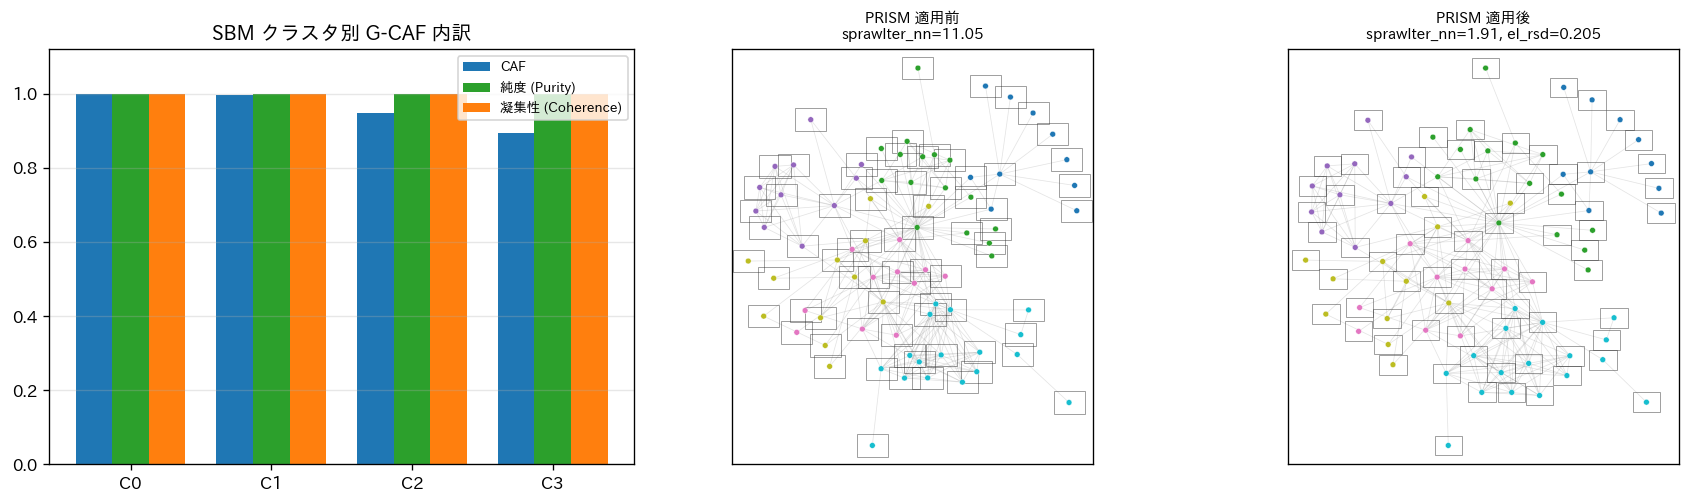

In [ ]:
# Build synthetic 4-cluster SBM (N=160) with planted ground-truth community labels
sizes_sbm = [40, 40, 40, 40]
probs_sbm = [
    [0.24, 0.015, 0.015, 0.015],
    [0.015, 0.24, 0.015, 0.015],
    [0.015, 0.015, 0.24, 0.015],
    [0.015, 0.015, 0.015, 0.24],
]
nx_sbm = nx.stochastic_block_model(sizes_sbm, probs_sbm, seed=42)
g_sbm_raw, sbm_nodes = from_networkx(nx_sbm)
g_sbm, lcc_idx = g_sbm_raw.largest_connected_component()
true_labels_sbm = np.array([nx_sbm.nodes[sbm_nodes[int(i)]]["block"] for i in lcc_idx], dtype=np.uint32)

# Layout SBM with IbUmapSolver for strong cluster separation
l_sbm = eg.pivot_mds_init(g_sbm, num_pivots=32, seed=42)
eg.IbUmapSolver(g_sbm, backend="ibfft", n_epochs=200, seed=42).run(l_sbm)

# 1) Patch NIG (adjusted for small graph vs defaults on dwt_1005)
leiden_les = eg.leiden_communities(g_les, seed=42)["labels"]
pnig_les_def = eg.adjusted_patch_nig(l_les, leiden_les)
pnig_les_tuned = eg.adjusted_patch_nig(l_les, leiden_les, patch_radius=32, canvas_size=256)
pnig_les_ms = eg.adjusted_patch_nig_multiscale(l_les, leiden_les, radii=(16, 32, 64), canvas_size=256)
pnig_dwt_ms = eg.adjusted_patch_nig_multiscale(l_dwt_sgd, labels_dwt)
print(f"lesmis adjusted_patch_nig: default(r=8,c=2048)={pnig_les_def:.4f} -> tuned(r=32,c=256)={pnig_les_tuned:.4f}")
print("lesmis multiscale:", {k: round(v, 4) for k, v in pnig_les_ms.items()})
print("dwt_1005 multiscale (defaults):", {k: round(v, 4) for k, v in pnig_dwt_ms.items()})

# 2) G-CAF & per-cluster breakdown
caf_val = eg.cluster_area_faithfulness(l_sbm, true_labels_sbm)
caf_det = eg.cluster_area_faithfulness_detail(l_sbm, true_labels_sbm, return_per_cluster=True)
print(f"\nSBM CAF={caf_val:.4f}, purity_adj={caf_det['purity_adj']:.4f}, prop_vis={caf_det['prop_vis']:.4f}")
print("Per-cluster IDs:", caf_det["cluster_ids"], "caf_per_cluster:", np.round(caf_det["caf_per_cluster"], 4))

# 3) Partition agreement & cluster quality baselines
leiden_sbm = eg.leiden_communities(g_sbm, seed=42)["labels"]
pa_leiden = eg.partition_agreement(true_labels_sbm, leiden_sbm)
cq_km = eg.cq_kmeans(l_sbm, true_labels_sbm, n_init=5, max_iters=100, seed=42)
cq_hc = eg.cq_hac(l_sbm, true_labels_sbm)
dsc_val = eg.distance_consistency(l_sbm, true_labels_sbm)
dc_val = eg.distribution_consistency(l_sbm, true_labels_sbm, 20)
cdm_val, hdm_val = eg.class_density_measure(l_sbm, true_labels_sbm, grid_size=64)
s_knn = eg.sepme_knng(l_sbm, true_labels_sbm, 2)
s_rng = eg.sepme_rng(l_sbm, true_labels_sbm)
s_gab = eg.sepme_gab(l_sbm, true_labels_sbm)
s_gong = eg.sepme_gong(l_sbm, true_labels_sbm, 0.35)
nh_val = eg.neighborhood_hit(l_sbm, true_labels_sbm, 7)
sil_val = eg.silhouette_score(l_sbm, true_labels_sbm)
ch_val = eg.calinski_harabasz_score(l_sbm, true_labels_sbm)
db_val = eg.davies_bouldin_score(l_sbm, true_labels_sbm)
pdoe_val = eg.pairwise_distance_overlap_error(l_sbm, true_labels_sbm, 100)

print("partition_agreement(true, leiden):", {k: round(v, 4) for k, v in pa_leiden.items()})
print("cq_kmeans:", {k: round(v, 4) for k, v in cq_km.items()})
print("cq_hac   :", {k: round(v, 4) for k, v in cq_hc.items()})
print(
    f"DSC={dsc_val:.4f}, DC={dc_val:.4f}, CDM={cdm_val:.4f}, HDM={hdm_val:.4f}, "
    f"NH={nh_val:.4f}, Sil={sil_val:.4f}, CH={ch_val:.1f}, DB={db_val:.4f}, PDOE={pdoe_val:.4f}"
)
print(f"SepMe: knng={s_knn:.4f}, rng={s_rng:.4f}, gab={s_gab:.4f}, gong={s_gong:.4f}")

# 4) sprawlter_nn & nor_metrics (comparing graph=None vs graph=g)
sp_before = eg.sprawlter_nn(l_les, hw_les, hh_les)
sp_after = eg.sprawlter_nn(l_les_adj, hw_les, hh_les)
nor_no_g = eg.nor_metrics(l_les, l_les_adj, hw_les, hh_les, graph=None)
nor_with_g = eg.nor_metrics(l_les, l_les_adj, hw_les, hh_les, graph=g_les)
print(f"\nsprawlter_nn: before PRISM={sp_before:.4f} -> after PRISM={sp_after:.4f}")
print("nor_metrics(graph=None):", {k: round(v, 4) for k, v in nor_no_g.items()})
print("nor_metrics(graph=g)   :", {k: round(v, 4) for k, v in nor_with_g.items()})

# Plot per-cluster CAF breakdown on SBM & PRISM overlap removal before/after on lesmis
fig, axes = plt.subplots(1, 3, figsize=(15.0, 4.3))
c_ids = caf_det["cluster_ids"]
x_c = np.arange(len(c_ids))
w = 0.26
axes[0].bar(x_c - w, caf_det["caf_per_cluster"], width=w, label="CAF", color="#1f77b4")
axes[0].bar(x_c, caf_det["purity"], width=w, label="純度 (Purity)", color="#2ca02c")
axes[0].bar(x_c + w, caf_det["coherence"], width=w, label="凝集性 (Coherence)", color="#ff7f0e")
axes[0].set_xticks(x_c)
axes[0].set_xticklabels([f"C{int(cid)}" for cid in c_ids])
axes[0].set_ylim(0, 1.12)
axes[0].set_title("SBM クラスタ別 G-CAF 内訳")
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

for ax_idx, (lay, title_str) in enumerate(
    [(l_les, f"PRISM 適用前\nsprawlter_nn={sp_before:.2f}"), (l_les_adj, f"PRISM 適用後\nsprawlter_nn={sp_after:.2f}, el_rsd={nor_with_g['el_rsd']:.3f}")],
    start=1,
):
    c_arr = lay.coords(copy=False)
    plot_layout(g_les, lay, ax=axes[ax_idx], labels=leiden_les, title=title_str, node_size=12, edge_alpha=0.2)
    for i in range(g_les.num_nodes):
        axes[ax_idx].add_patch(
            Rectangle((c_arr[i, 0] - hw_les[i], c_arr[i, 1] - hh_les[i]), 2 * hw_les[i], 2 * hh_les[i], fill=False, edgecolor="#333333", linewidth=0.5, alpha=0.55)
        )
plt.tight_layout()
plt.show()

## 7. 7 アルゴリズム横断比較ベンチマーク（`dwt_1005` & 4 クラスタ SBM）

最後に、設計思想の異なる 7 つのグラフレイアウトアルゴリズムを同一データ・同一シード条件で実行し、計算時間と多軸品質指標（`evaluate_metrics`）を定量比較します。

1. `SgdSolver.full`: 全ペア確率的勾配降下法（ストレス最小化の標準）
2. `StressMajorizationSolver`: ストレスマジョリゼーション（幾何的一貫性）
3. `TsNetSolver.pure_2hop`: 近傍保持（1+2 ホップ適応的 tsNET + FFT 反発）
4. `IbUmapSolver`: 補間ベース UMAP（高クラスタ分離）
5. `ForceAtlas2Solver`: 力学モデル ForceAtlas2（高速・ハブ強調）
6. `YifanHuSolver`: マルチレベル Barnes-Hut 力学モデル
7. `SgdSolver.sparse_barrier_dog`: $O(|E|)$ Chebyshev DoG + 3 階層スパースバリア SGD

In [ ]:
def run_benchmark_suite(graph: eg.CsrGraph, labels: np.ndarray, dataset_name: str):
    '''Run all 7 layout solvers from identical PivotMDS initialization and evaluate metrics.'''
    init_base = eg.pivot_mds_init(graph, num_pivots=50, seed=42).coords(copy=True)

    solver_specs = [
        ("SGD Full", lambda g, l: eg.SgdSolver.full(g, t_max=60, seed=42).run(l)),
        ("StressMaj", lambda g, l: eg.StressMajorizationSolver.from_graph(g, max_iterations=100).run(l)),
        ("TsNet 2hop", lambda g, l: eg.TsNetSolver.pure_2hop(g, backend="fft", iterations_stage1=100, iterations_stage2=100, iterations_stage3=150, seed=42).run(l)),
        ("IbUMAP", lambda g, l: eg.IbUmapSolver(g, backend="ibfft", n_epochs=200, seed=42).run(l)),
        ("ForceAtlas2", lambda g, l: eg.ForceAtlas2Solver(g, iterations=200, seed=42).run(l)),
        ("YifanHu", lambda g, l: eg.YifanHuSolver(g, max_iterations_per_level=200, seed=42).run(l)),
        ("BarrierDoG", lambda g, l: eg.SgdSolver.sparse_barrier_dog(g, t_max=60, seed=42).run(l)),
    ]

    targets = [
        "scale_normalized_stress",
        "crosslessness",
        "neighborhood_preservation_2hop",
        "landmark_stratified_rta",
        "cluster_area_faithfulness",
        "neighborhood_hit",
        "silhouette",
    ]

    results = []
    layouts = {}
    for name, fn in solver_specs:
        lay = eg.Layout2d.from_coords(init_base.copy())
        t0 = time.perf_counter()
        fn(graph, lay)
        elapsed_ms = (time.perf_counter() - t0) * 1000.0
        metrics = eg.evaluate_metrics(
            graph,
            lay,
            targets,
            community_labels=labels,
            num_landmarks=32,
            num_triplets=40000,
            seed=42,
        )
        metrics["runtime_ms"] = elapsed_ms
        metrics["name"] = name
        results.append(metrics)
        layouts[name] = lay

    print(f"\n=== Benchmark Results: {dataset_name} (N={graph.num_nodes}, E={graph.num_edges}) ===")
    print(f"{'Solver':<13} {'ms':>7} {'SNS(↓)':>8} {'CrossL(↑)':>10} {'NP2(↑)':>8} {'RTA(↑)':>8} {'CAF(↑)':>8} {'NH(↑)':>8} {'Sil(↑)':>8}")
    print("-" * 86)
    for r in results:
        print(
            f"{r['name']:<13} {r['runtime_ms']:>7.1f} {r['scale_normalized_stress']:>8.4f} "
            f"{r['crosslessness']:>10.4f} {r['neighborhood_preservation_2hop']:>8.4f} "
            f"{r['landmark_stratified_rta']:>8.4f} {r['cluster_area_faithfulness']:>8.4f} "
            f"{r['neighborhood_hit']:>8.4f} {r['silhouette']:>8.4f}"
        )
    return results, layouts


res_dwt, layouts_dwt = run_benchmark_suite(g_dwt, labels_dwt, "dwt_1005")
res_sbm, layouts_sbm = run_benchmark_suite(g_sbm, true_labels_sbm, "4-Cluster SBM")


=== Benchmark Results: dwt_1005 (N=1005, E=3808) ===
Solver             ms   SNS(↓)  CrossL(↑)   NP2(↑)   RTA(↑)   CAF(↑)    NH(↑)   Sil(↑)
--------------------------------------------------------------------------------------
SGD Full       1181.9   0.0212     0.9666   0.5629   0.9595   0.8036   0.8932   0.3461
StressMaj      2160.4   0.0213     0.9667   0.5610   0.9602   0.8050   0.9015   0.3509
TsNet 2hop     2881.1   0.0502     0.9690   0.7018   0.9524   0.8677   0.9150   0.4023
IbUMAP         1248.2   0.0366     0.9679   0.4586   0.9471   0.8017   0.9414   0.4257
ForceAtlas2     177.0   0.0327     0.9692   0.4918   0.9513   0.7729   0.9274   0.3572
YifanHu         316.2   0.0289     0.9687   0.5014   0.9535   0.8103   0.9279   0.3642
BarrierDoG      132.9   0.0341     0.9652   0.5366   0.9520   0.8143   0.9207   0.3851



=== Benchmark Results: 4-Cluster SBM (N=160, E=920) ===
Solver             ms   SNS(↓)  CrossL(↑)   NP2(↑)   RTA(↑)   CAF(↑)    NH(↑)   Sil(↑)
--------------------------------------------------------------------------------------
SGD Full         25.9   0.1365     0.7888   0.5690   0.8645   0.8104   0.8696   0.3880
StressMaj        61.6   0.1371     0.7890   0.5700   0.8680   0.8243   0.8848   0.3941
TsNet 2hop     1310.1   0.1839     0.8090   0.5790   0.8433   0.9596   0.9955   0.6491
IbUMAP          924.8   0.1974     0.8078   0.5640   0.8507   0.9603   0.9991   0.7198
ForceAtlas2      17.1   0.1594     0.8051   0.5800   0.8642   0.9613   0.9946   0.6117
YifanHu          36.6   0.1467     0.7918   0.5655   0.8524   0.8944   0.9696   0.5048
BarrierDoG       31.4   0.2088     0.7681   0.5157   0.8221   0.7856   0.9250   0.3527


### ベンチマーク可視化 1: `dwt_1005` の 7 手法レイアウト一覧と指標別棒グラフ

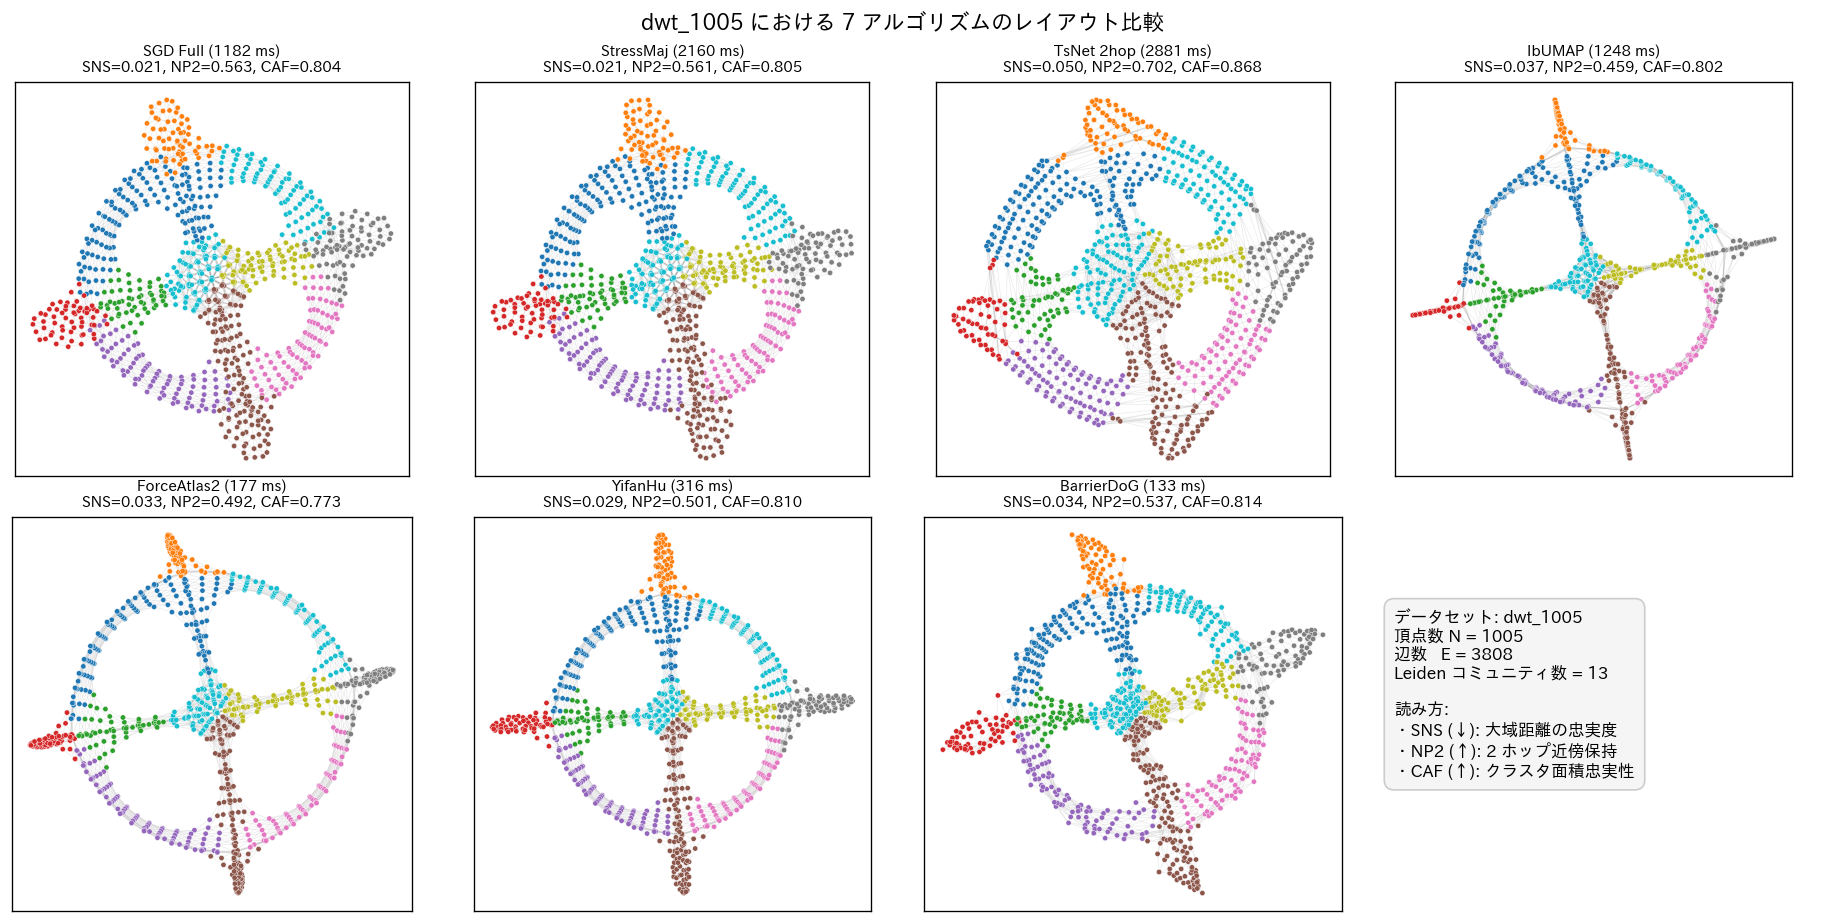

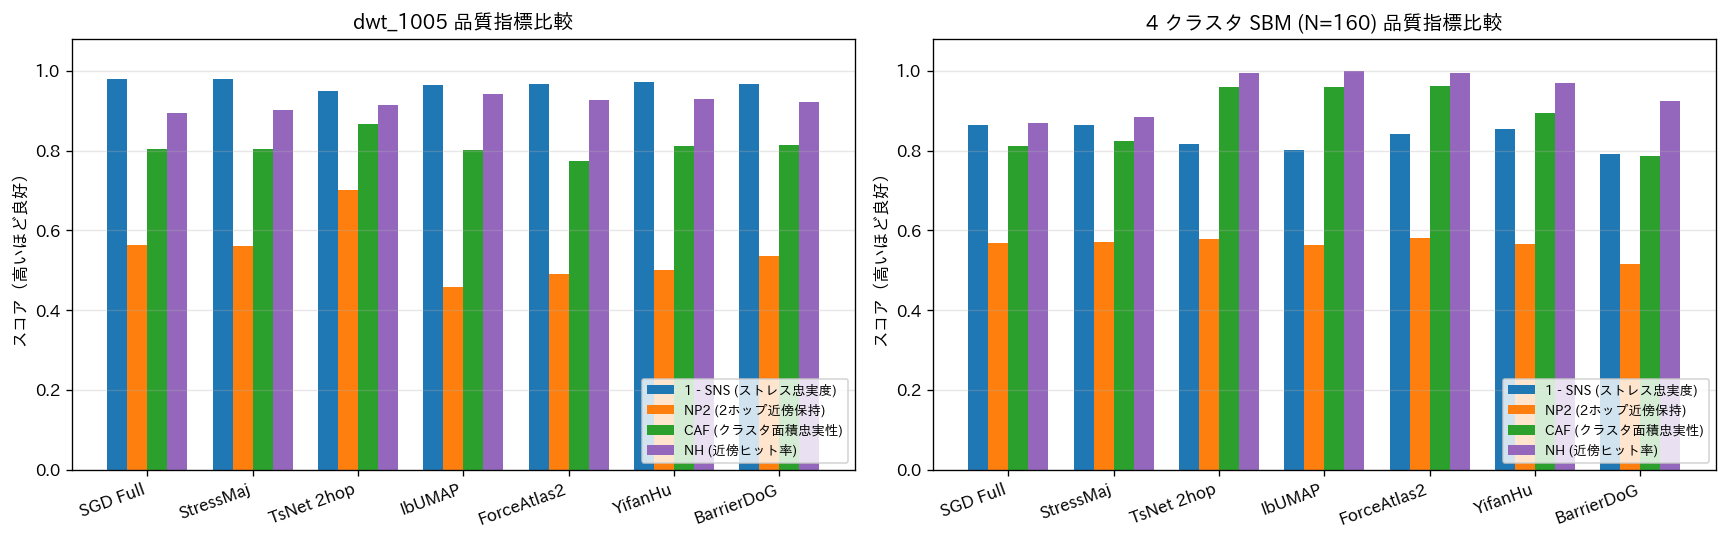

In [ ]:
# 1) 2x4 grid of the 7 layouts on dwt_1005 (colored by Leiden communities)
fig, axes = plt.subplots(2, 4, figsize=(15.5, 7.8))
axes_flat = axes.ravel()
for idx, r in enumerate(res_dwt):
    name = r["name"]
    plot_layout(
        g_dwt,
        layouts_dwt[name],
        ax=axes_flat[idx],
        labels=labels_dwt,
        node_size=10.0,
        edge_alpha=0.14,
        title=f"{name} ({r['runtime_ms']:.0f} ms)\nSNS={r['scale_normalized_stress']:.3f}, NP2={r['neighborhood_preservation_2hop']:.3f}, CAF={r['cluster_area_faithfulness']:.3f}",
    )

# Use 8th panel for concise legend / benchmark summary
ax_info = axes_flat[7]
ax_info.axis("off")
ax_info.text(
    0.05,
    0.55,
    "データセット: dwt_1005\n"
    f"頂点数 N = {g_dwt.num_nodes}\n"
    f"辺数   E = {g_dwt.num_edges}\n"
    f"Leiden コミュニティ数 = {leiden_dwt['num_communities']}\n\n"
    "読み方:\n"
    "・SNS (↓): 大域距離の忠実度\n"
    "・NP2 (↑): 2 ホップ近傍保持\n"
    "・CAF (↑): クラスタ面積忠実性",
    va="center",
    fontsize=10,
    bbox={"boxstyle": "round,pad=0.6", "facecolor": "#f5f5f5", "edgecolor": "#cccccc"},
)
fig.suptitle("dwt_1005 における 7 アルゴリズムのレイアウト比較", fontsize=13)
plt.tight_layout()
plt.show()

# 2) Grouped bar charts comparing key metrics across dwt_1005 and 4-Cluster SBM
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.6))
solver_names = [r["name"] for r in res_dwt]
x = np.arange(len(solver_names))
bw = 0.19

for ax, res_list, ds_title in [
    (axes[0], res_dwt, "dwt_1005 品質指標比較"),
    (axes[1], res_sbm, "4 クラスタ SBM (N=160) 品質指標比較"),
]:
    sns_inv = [1.0 - r["scale_normalized_stress"] for r in res_list]
    np2_vals = [r["neighborhood_preservation_2hop"] for r in res_list]
    caf_vals = [r["cluster_area_faithfulness"] for r in res_list]
    nh_vals = [r["neighborhood_hit"] for r in res_list]

    ax.bar(x - 1.5 * bw, sns_inv, width=bw, label="1 - SNS (ストレス忠実度)", color="#1f77b4")
    ax.bar(x - 0.5 * bw, np2_vals, width=bw, label="NP2 (2ホップ近傍保持)", color="#ff7f0e")
    ax.bar(x + 0.5 * bw, caf_vals, width=bw, label="CAF (クラスタ面積忠実性)", color="#2ca02c")
    ax.bar(x + 1.5 * bw, nh_vals, width=bw, label="NH (近傍ヒット率)", color="#9467bd")
    ax.set_xticks(x)
    ax.set_xticklabels(solver_names, rotation=20, ha="right")
    ax.set_ylim(0.0, 1.08)
    ax.set_ylabel("スコア（高いほど良好）")
    ax.set_title(ds_title)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

### ベンチマーク可視化 2: 正規化レーダーチャートとトレードオフ散布図（`SNS` vs `NP2`・`CAF` vs 計算時間）

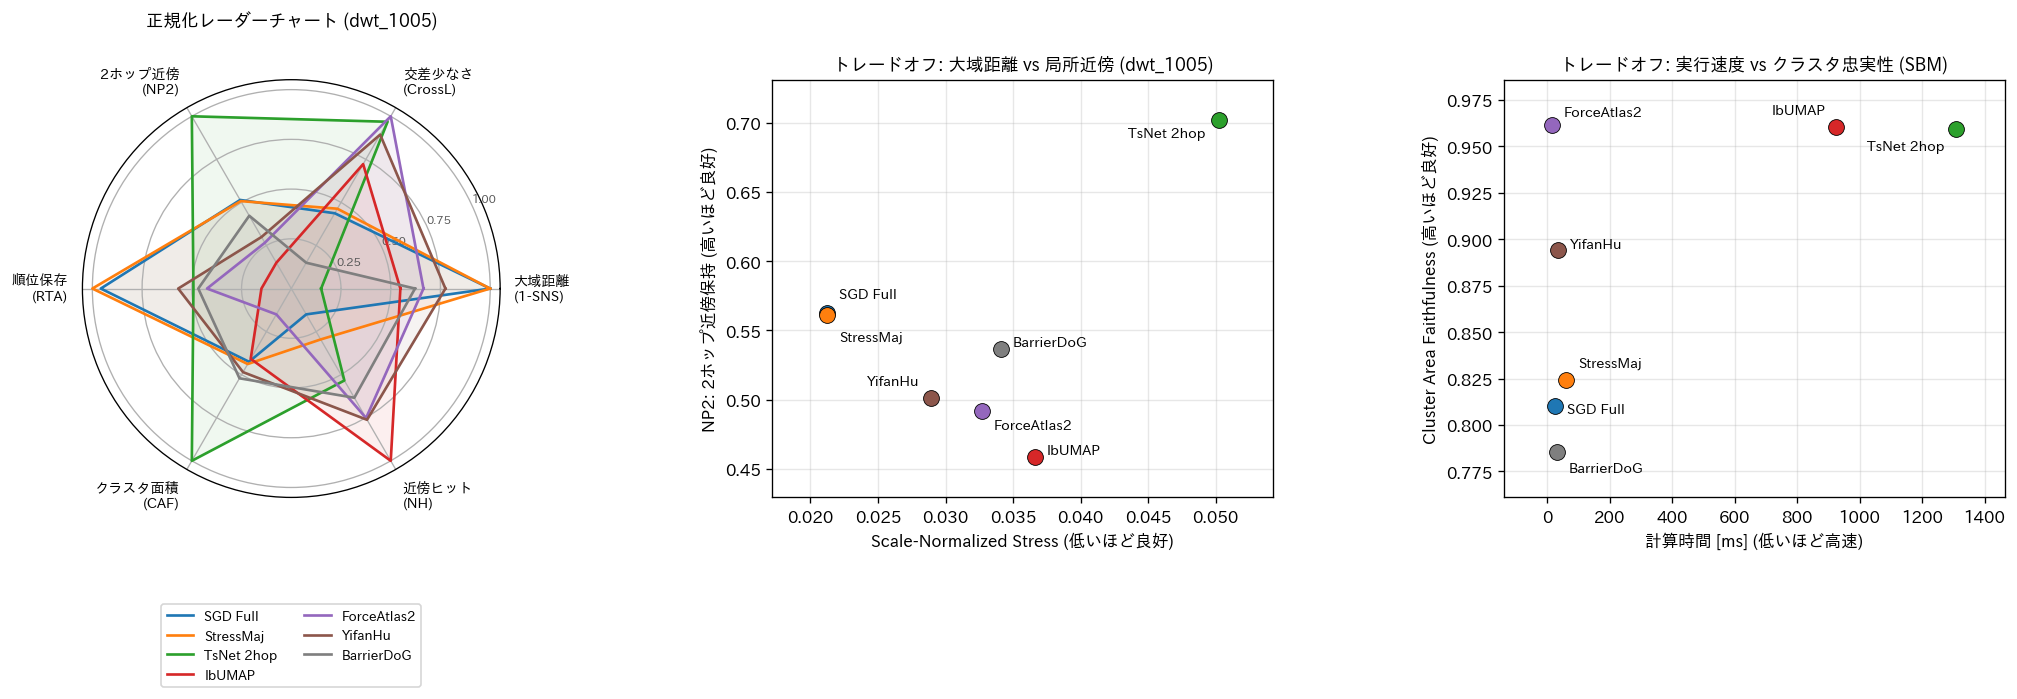

In [ ]:
# 1) Normalized radar chart on dwt_1005 (6 axes, min-max scaled across solvers so higher is better)
radar_axes = [
    ("大域距離\n(1-SNS)", lambda r: 1.0 - r["scale_normalized_stress"]),
    ("交差少なさ\n(CrossL)", lambda r: r["crosslessness"]),
    ("2ホップ近傍\n(NP2)", lambda r: r["neighborhood_preservation_2hop"]),
    ("順位保存\n(RTA)", lambda r: r["landmark_stratified_rta"]),
    ("クラスタ面積\n(CAF)", lambda r: r["cluster_area_faithfulness"]),
    ("近傍ヒット\n(NH)", lambda r: r["neighborhood_hit"]),
]

raw_mat = np.array([[fn(r) for _, fn in radar_axes] for r in res_dwt], dtype=float)
col_min = raw_mat.min(axis=0)
col_max = raw_mat.max(axis=0)
norm_mat = (raw_mat - col_min) / np.maximum(col_max - col_min, 1e-12)
# Map to [0.15, 1.0] for clean polygon visibility
norm_mat = 0.15 + 0.85 * norm_mat

angles = np.linspace(0.0, 2.0 * np.pi, len(radar_axes), endpoint=False).tolist()
angles_closed = angles + [angles[0]]

fig = plt.figure(figsize=(17.6, 5.9))
fig.subplots_adjust(left=0.05, right=0.98, bottom=0.25, top=0.84, wspace=0.46)

# Left: Radar chart with angle-aware outer label placement
ax_rad = fig.add_subplot(131, polar=True)
palette = plt.cm.tab10(np.linspace(0, 0.7, len(res_dwt)))
for idx, r in enumerate(res_dwt):
    vals = norm_mat[idx].tolist() + [norm_mat[idx, 0]]
    ax_rad.plot(angles_closed, vals, linewidth=1.6, color=palette[idx], label=r["name"])
    ax_rad.fill(angles_closed, vals, color=palette[idx], alpha=0.07)

ax_rad.set_xticks(angles)
ax_rad.set_xticklabels([])
ax_rad.set_ylim(0.0, 1.05)
ax_rad.set_yticks([0.25, 0.5, 0.75, 1.0])
ax_rad.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=7, color="#555555")
ax_rad.set_rlabel_position(25)

for angle, (lbl, _) in zip(angles, radar_axes):
    cos_a, sin_a = np.cos(angle), np.sin(angle)
    ha = "center" if abs(cos_a) < 0.15 else ("left" if cos_a > 0 else "right")
    va = "center" if abs(sin_a) < 0.15 else ("bottom" if sin_a > 0 else "top")
    ax_rad.text(angle, 1.12, lbl, fontsize=8.5, ha=ha, va=va, clip_on=False)

ax_rad.set_title("正規化レーダーチャート (dwt_1005)", pad=32, fontsize=10.5)
ax_rad.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, fontsize=8)

# Middle: Trade-off scatter (SNS vs NP2 on dwt_1005) with per-solver offsets
sc1_offsets = {
    "SGD Full": (7, 7, "left", "bottom"),
    "StressMaj": (7, -9, "left", "top"),
    "TsNet 2hop": (-8, -4, "right", "top"),
    "IbUMAP": (7, 4, "left", "center"),
    "ForceAtlas2": (7, -5, "left", "top"),
    "YifanHu": (-7, 6, "right", "bottom"),
    "BarrierDoG": (7, 4, "left", "center"),
}
ax_sc1 = fig.add_subplot(132)
for idx, r in enumerate(res_dwt):
    x_val, y_val = r["scale_normalized_stress"], r["neighborhood_preservation_2hop"]
    ax_sc1.scatter(x_val, y_val, s=90, color=palette[idx], edgecolors="black", linewidths=0.5, zorder=3)
    dx, dy, ha, va = sc1_offsets.get(r["name"], (6, 4, "left", "center"))
    ax_sc1.annotate(
        r["name"],
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha=ha,
        va=va,
        fontsize=8.5,
    )
ax_sc1.margins(x=0.14, y=0.12)
ax_sc1.set_xlabel("Scale-Normalized Stress (低いほど良好)")
ax_sc1.set_ylabel("NP2: 2ホップ近傍保持 (高いほど良好)")
ax_sc1.set_title("トレードオフ: 大域距離 vs 局所近傍 (dwt_1005)", fontsize=10.5)
ax_sc1.grid(alpha=0.3)

# Right: Trade-off scatter (Runtime vs CAF on SBM) with per-solver offsets
sc2_offsets = {
    "SGD Full": (7, -2, "left", "center"),
    "StressMaj": (7, 6, "left", "bottom"),
    "TsNet 2hop": (-7, -7, "right", "top"),
    "IbUMAP": (-6, 6, "right", "bottom"),
    "ForceAtlas2": (7, 4, "left", "bottom"),
    "YifanHu": (7, 3, "left", "center"),
    "BarrierDoG": (7, -6, "left", "top"),
}
ax_sc2 = fig.add_subplot(133)
for idx, r in enumerate(res_sbm):
    x_val, y_val = r["runtime_ms"], r["cluster_area_faithfulness"]
    ax_sc2.scatter(x_val, y_val, s=90, color=palette[idx], edgecolors="black", linewidths=0.5, zorder=3)
    dx, dy, ha, va = sc2_offsets.get(r["name"], (6, 4, "left", "center"))
    ax_sc2.annotate(
        r["name"],
        (x_val, y_val),
        textcoords="offset points",
        xytext=(dx, dy),
        ha=ha,
        va=va,
        fontsize=8.5,
    )
ax_sc2.margins(x=0.12, y=0.14)
ax_sc2.set_xlabel("計算時間 [ms] (低いほど高速)")
ax_sc2.set_ylabel("Cluster Area Faithfulness (高いほど良好)")
ax_sc2.set_title("トレードオフ: 実行速度 vs クラスタ忠実性 (SBM)", fontsize=10.5)
ax_sc2.grid(alpha=0.3)

plt.show()
